Bài 5 — Cùng dữ liệu, histogram có thể kể những câu chuyện khác nhau.
1. Vẽ bốn histogram của cùng x, lần lượt với bin width = 5, 15, 30 và 60 phút. Giữ
cùng miền trục ngang [-30, 150] để việc so sánh có ý nghĩa.


In [2]:
!pip install plotnine

^C
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
from plotnine import *
flights = pd.read_csv("nycflights.csv")

In [5]:
import pandas as pd
from plotnine import *

flights = pd.read_csv("nycflights.csv")

x = flights["arr_delay"].dropna()
x = x[(x >= -30) & (x < 150)]

df = pd.DataFrame({"x": x})

df.head()

,x
0,-4
1,10
2,11
4,-8
5,3


C:\Users\Windows\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\plotnine\layer.py:374: PlotnineWarning: geom_histogram : Removed 2 rows containing missing values.


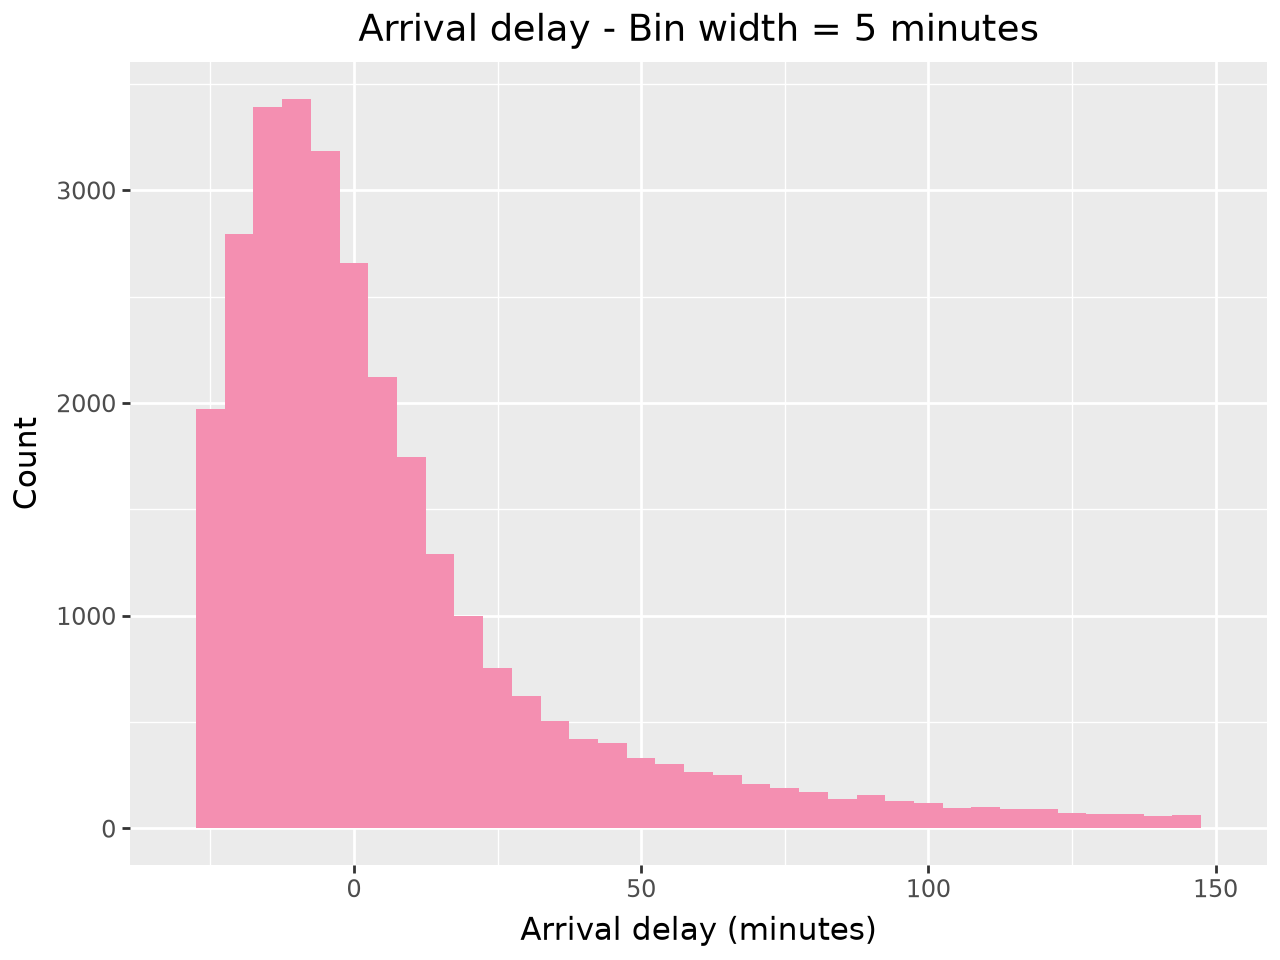

In [ ]:
import pandas as pd
from plotnine import *
flights = pd.read_csv("nycflights.csv")
x = flights["arr_delay"].dropna()
x = x[(x >= -30) & (x < 150)]
df = pd.DataFrame({"x": x})
(
    ggplot(df, aes(x="x"))
    + geom_histogram(binwidth=5, fill="#F48FB1")
    + scale_x_continuous(limits=(-30, 150))
    + labs(
        title="Arrival delay - Bin width = 5 minutes",
        x="Arrival delay (minutes)",
        y="Count"
    )
)

C:\Users\Windows\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\plotnine\layer.py:374: PlotnineWarning: geom_histogram : Removed 2 rows containing missing values.


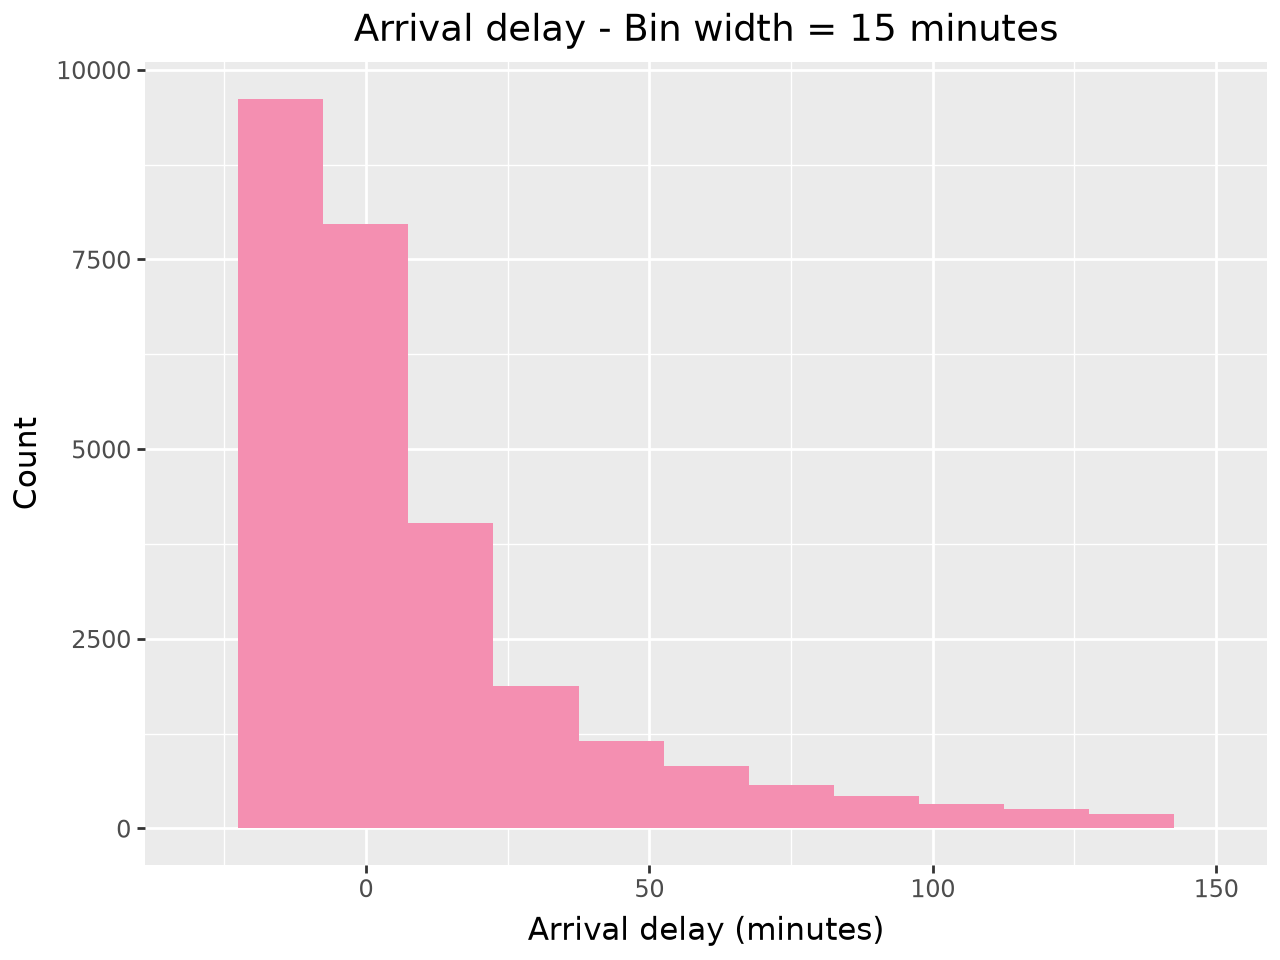

In [11]:
(
    ggplot(df, aes(x="x"))
    + geom_histogram(binwidth=15, fill="#F48FB1")
    + scale_x_continuous(limits=(-30, 150))
    + labs(
        title="Arrival delay - Bin width = 15 minutes",
        x="Arrival delay (minutes)",
        y="Count"
    )
)

C:\Users\Windows\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\plotnine\layer.py:374: PlotnineWarning: geom_histogram : Removed 2 rows containing missing values.


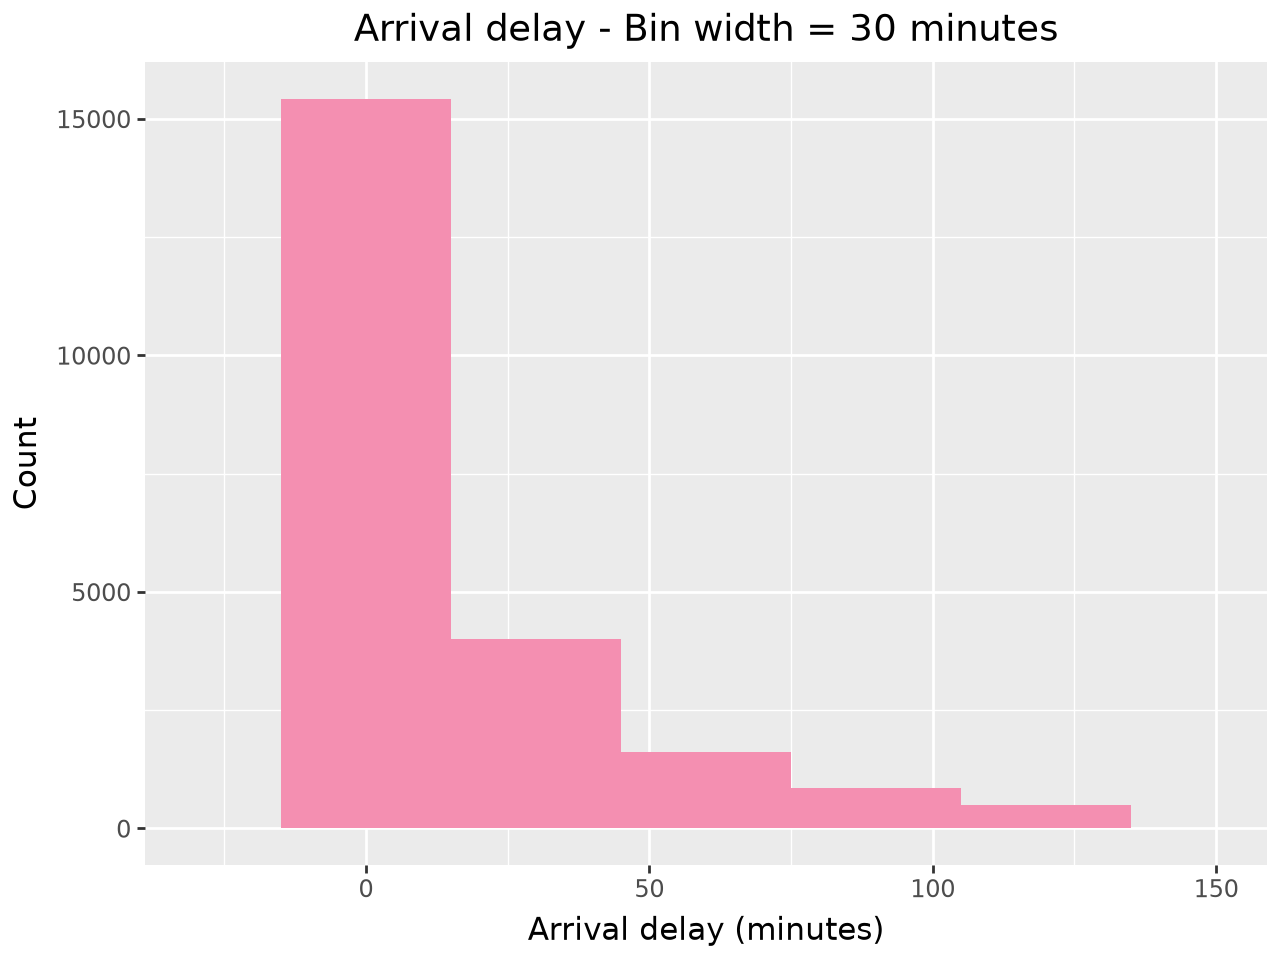

In [13]:
(
    ggplot(df, aes(x="x"))
    + geom_histogram(binwidth=30, fill="#F48FB1")
    + scale_x_continuous(limits=(-30, 150))
    + labs(
        title="Arrival delay - Bin width = 30 minutes",
        x="Arrival delay (minutes)",
        y="Count"
    )
)

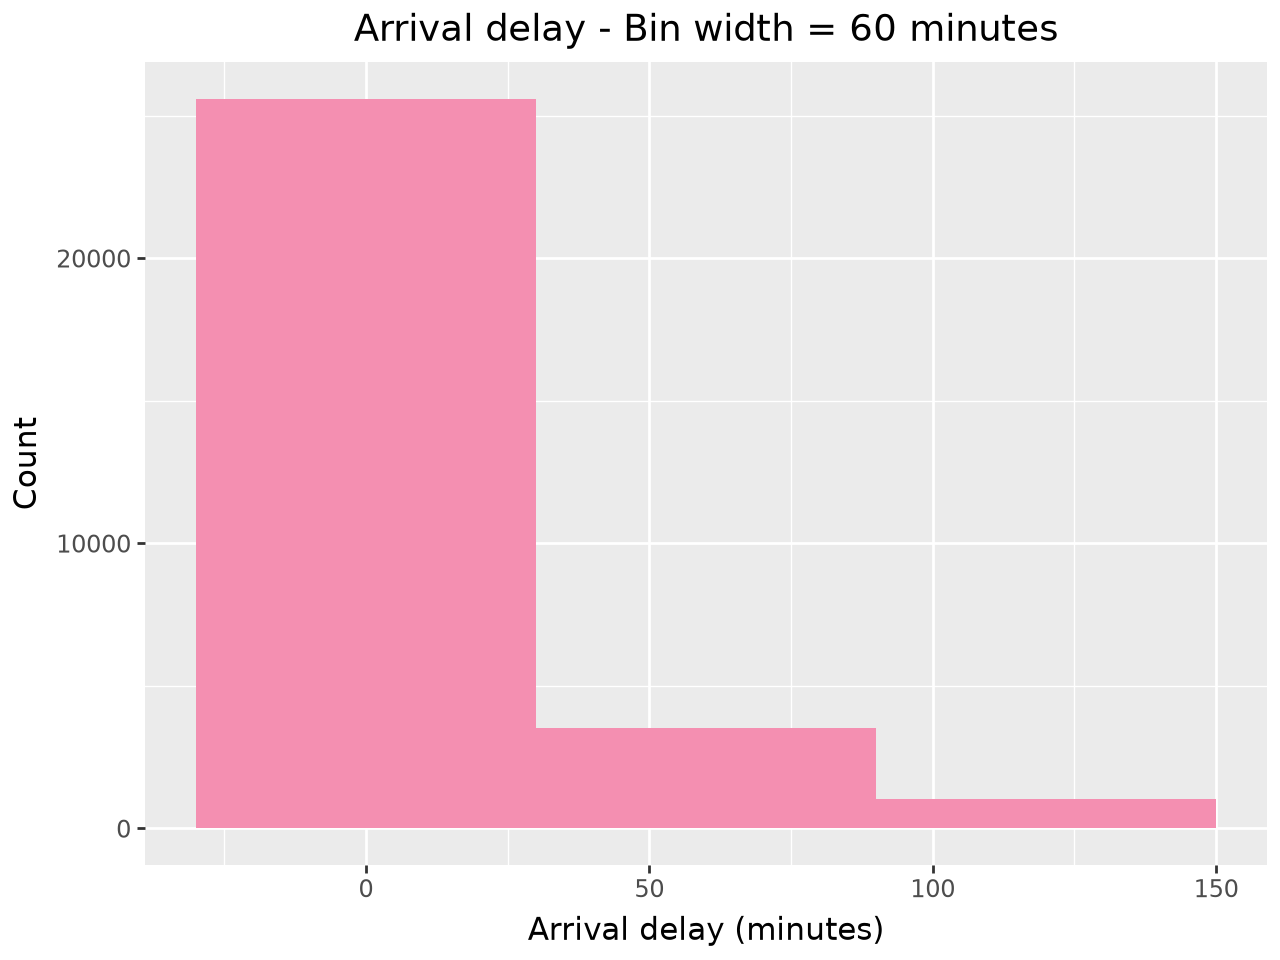

In [14]:
(
    ggplot(df, aes(x="x"))
    + geom_histogram(binwidth=60, fill="#F48FB1")
    + scale_x_continuous(limits=(-30, 150))
    + labs(
        title="Arrival delay - Bin width = 60 minutes",
        x="Arrival delay (minutes)",
        y="Count"
    )
)

In [ ]:
import pandas as pd
flights = pd.read_csv("nycflights.csv")
x = flights["arr_delay"].dropna()
x = x[(x >= -30) & (x < 150)]
print(f"Mean = {x.mean():.2f}")
print(f"Median = {x.median():.2f}")
print(f"Sample SD = {x.std():.2f}")
print(f"IQR = {x.quantile(0.75) - x.quantile(0.25):.2f}")

Mean = 5.75
Median = -3.00
Sample SD = 31.60
IQR = 29.00


Bài 6 — Một spike ở 40 giờ nói lên điều gì? ����
Dùng bộ dữ liệu gss2010 của OpenIntro, trích từ General Social Survey 2010. Biến hrs1 là số
giờ làm việc trong một tuần mà người trả lời báo cáo.
1. 1. Vẽ hai histogram của hrs1:
• bin width = 1 giờ;

• bin width = 5 giờ.



In [2]:
import pandas as pd
from plotnine import *
gss = pd.read_csv("gss2010.csv")
hrs = gss["hrs1"].dropna()

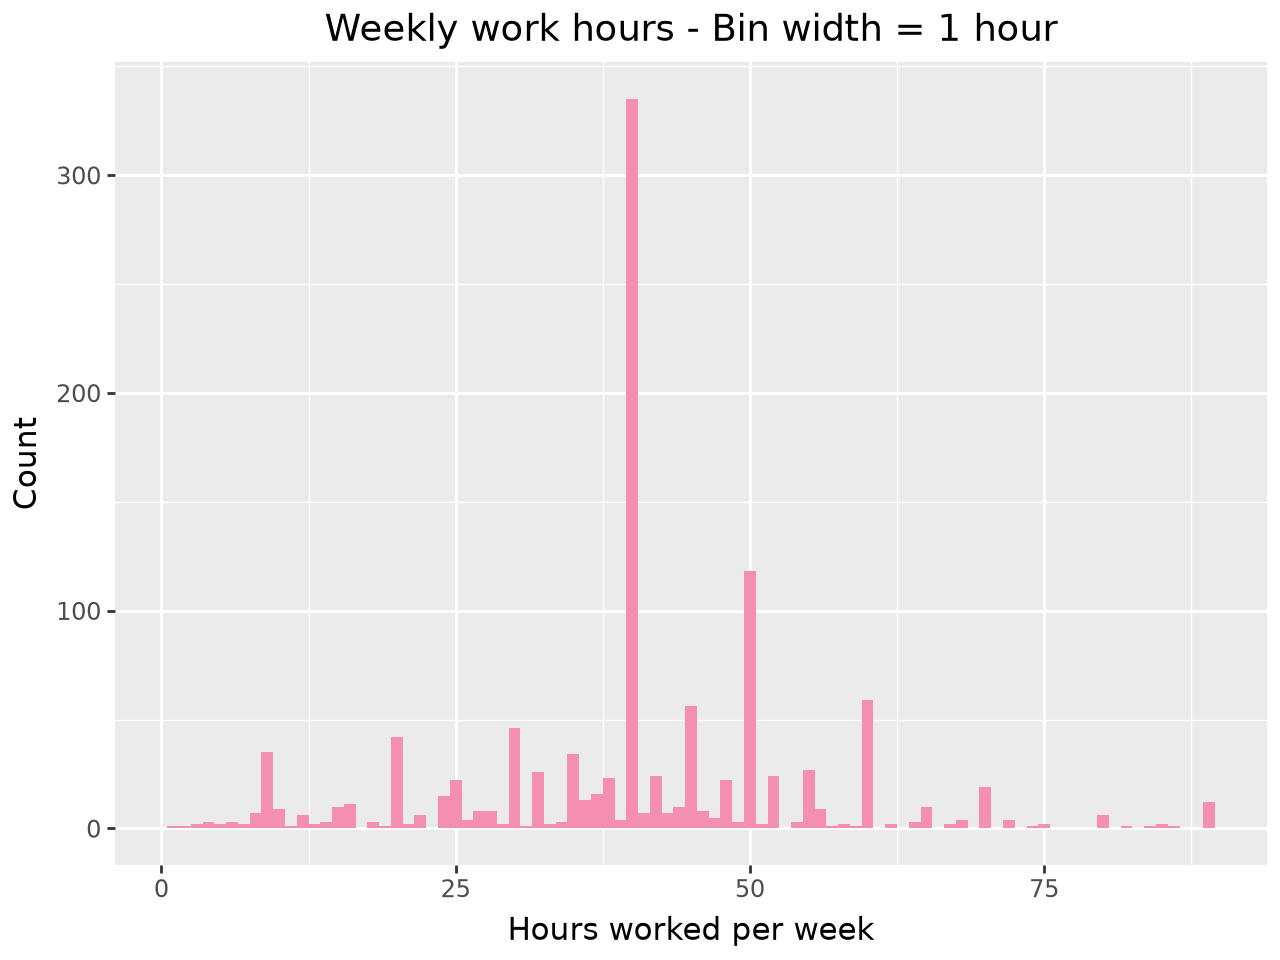

In [3]:
(
    ggplot(pd.DataFrame({"hrs": hrs}), aes(x="hrs"))
    + geom_histogram(binwidth=1, fill="#F48FB1")
    + labs(
        title="Weekly work hours - Bin width = 1 hour",
        x="Hours worked per week",
        y="Count"
    )
)

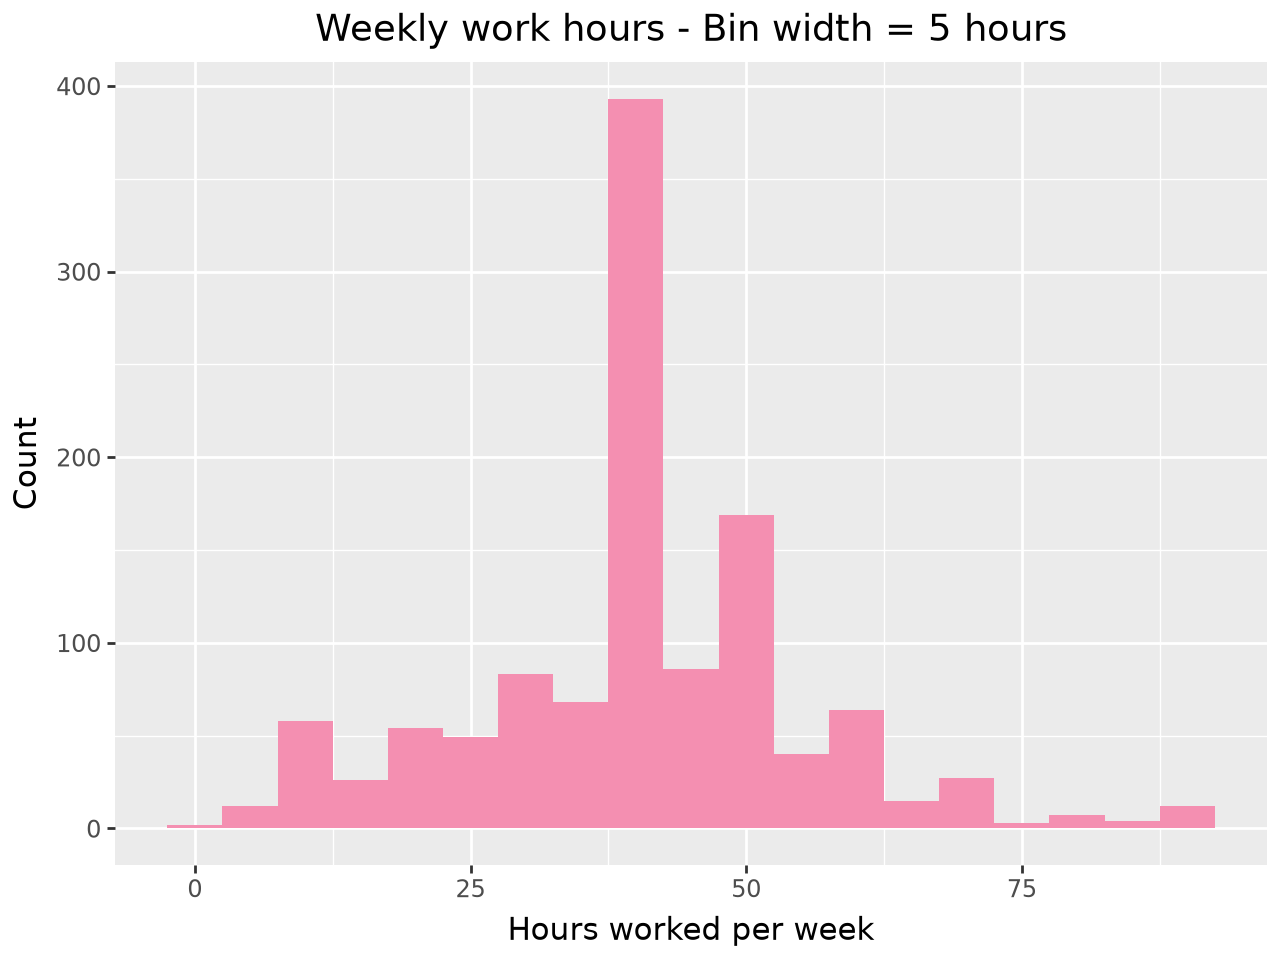

In [4]:
(
    ggplot(pd.DataFrame({"hrs": hrs}), aes(x="hrs"))
    + geom_histogram(binwidth=5, fill="#F48FB1")
    + labs(
        title="Weekly work hours - Bin width = 5 hours",
        x="Hours worked per week",
        y="Count"
    )
)

6.2. Tính số và tỉ lệ người báo cáo chính xác 39, 40, 41 giờ. So sánh ba giá trị này.


In [5]:
counts = hrs.value_counts().sort_index()

for h in [39, 40, 41]:
    n = counts.get(h, 0)
    p = n / len(hrs) * 100
    print(f"{h} giờ: {n} người, {p:.2f}%")

39 giờ: 4 người, 0.34%
40 giờ: 335 người, 28.58%
41 giờ: 7 người, 0.60%


Bài 7 — Con người có báo cáo số tròn không? �����
Dùng bộ dữ liệu gpa_study_hours của OpenIntro. study_hours là số giờ học mỗi tuần do
sinh viên tự báo cáo.
1. Lập bảng tần số của chữ số hàng đơn vị của study_hours

In [21]:
import pandas as pd

gpa = pd.read_csv("gpa_study_hours.csv")
hrs = gpa["study_hours"].dropna()

last_digit = hrs.astype(int) % 10

freq = last_digit.value_counts().sort_index()
table = pd.DataFrame({
    "Frequency": freq,
    "Percent": (freq / len(hrs) * 100).round(2)
})

print(table)
# print(freq)

             Frequency  Percent
study_hours                    
0                   86    44.56
1                    4     2.07
2                   11     5.70
3                    2     1.04
4                   16     8.29
5                   42    21.76
6                    8     4.15
7                    7     3.63
8                   14     7.25
9                    3     1.55


7.3. Tính:
• tỉ lệ giá trị là bội của 5;
• tỉ lệ giá trị là bội của 10.


In [22]:
prop_5 = (hrs % 5 == 0).mean()
prop_10 = (hrs % 10 == 0).mean()

print(f"Bội của 5: {prop_5:.2%}")
print(f"Bội của 10: {prop_10:.2%}")

Bội của 5: 66.32%
Bội của 10: 44.56%


7.5. Tạo một phiên bản dữ liệu mới bằng cách làm tròn mọi giá trị study_hours tới 5 giờ
gần nhất.

In [26]:
hrs_round5 = (hrs / 5).round() * 5

7.6. Tính bốn đại lượng ở câu 5 cho dữ liệu gốc và dữ liệu làm tròn. 

In [27]:
def summary(x):
    return pd.Series({
        "Mean": x.mean(),
        "Median": x.median(),
        "Sample SD": x.std(),
        "IQR": x.quantile(0.75) - x.quantile(0.25)
    })

result = pd.DataFrame({
    "Original": summary(hrs),
    "Rounded to 5": summary(hrs_round5)
})

print(result.round(2))

           Original  Rounded to 5
Mean          17.48         17.49
Median        15.00         15.00
Sample SD     11.41         11.51
IQR           10.00         10.00


Bài 8 — “Hãng có nhiều chuyến trễ nhất là hãng tệ nhất” ��

In [30]:
import pandas as pd

flights = pd.read_csv("nycflights.csv")
df = flights.dropna(subset=["arr_delay"]).copy()
df["severe_delay"] = df["arr_delay"] >= 60

8.1. Với mỗi carrier, tính số chuyến trễ nghiêm trọng. Xếp hạng các hãng theo số đếm
này.

In [31]:
count_severe = (
    df.groupby("carrier")["severe_delay"]
      .sum()
      .sort_values(ascending=False)
)

print(count_severe)

carrier
EV    700
B6    519
UA    420
DL    286
MQ    236
AA    224
9E    183
WN    111
US     98
VX     35
FL     35
F9      6
YV      6
AS      3
OO      1
HA      1
Name: severe_delay, dtype: int64


8.2. Với mỗi carrier, tính:
• tổng số chuyến trong dữ liệu;
• tỉ lệ chuyến trễ nghiêm trọng trong hãng đó.

In [32]:
summary = (
    df.groupby("carrier")
      .agg(
          total_flights=("arr_delay", "size"),
          severe_delays=("severe_delay", "sum")
      )
)

summary["rate"] = (
    summary["severe_delays"] / summary["total_flights"] * 100
)

summary = summary.sort_values("rate", ascending=False)

print(summary.round(2))

         total_flights  severe_delays   rate
carrier                                     
OO                   3              1  33.33
EV                5142            700  13.61
FL                 307             35  11.40
YV                  53              6  11.32
9E                1696            183  10.79
B6                5376            519   9.65
MQ                2507            236   9.41
WN                1261            111   8.80
F9                  69              6   8.70
UA                5770            420   7.28
VX                 497             35   7.04
AA                3188            224   7.03
DL                4751            286   6.02
US                2015             98   4.86
AS                  66              3   4.55
HA                  34              1   2.94


Bài 9 — Cùng mean và SD, hình dạng vẫn có thể khác
Dùng dữ liệu Palmer Penguins đã xuất hiện trong Week 02, nhưng không chia theo loài.
Xét toàn bộ các giá trị hợp lệ của body_mass_g.


9.1.Histogram của tập dữ liệu


In [34]:
import numpy as np
import pandas as pd
from plotnine import *

url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"

penguins = pd.read_csv(url)

x = penguins["body_mass_g"].dropna()

x_bar = x.mean()

x_star = 2 * x_bar - x

In [35]:
df_x = pd.DataFrame({"mass": x})
df_star = pd.DataFrame({"mass": x_star})

C:\Users\Windows\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\plotnine\layer.py:374: PlotnineWarning: geom_histogram : Removed 2 rows containing missing values.


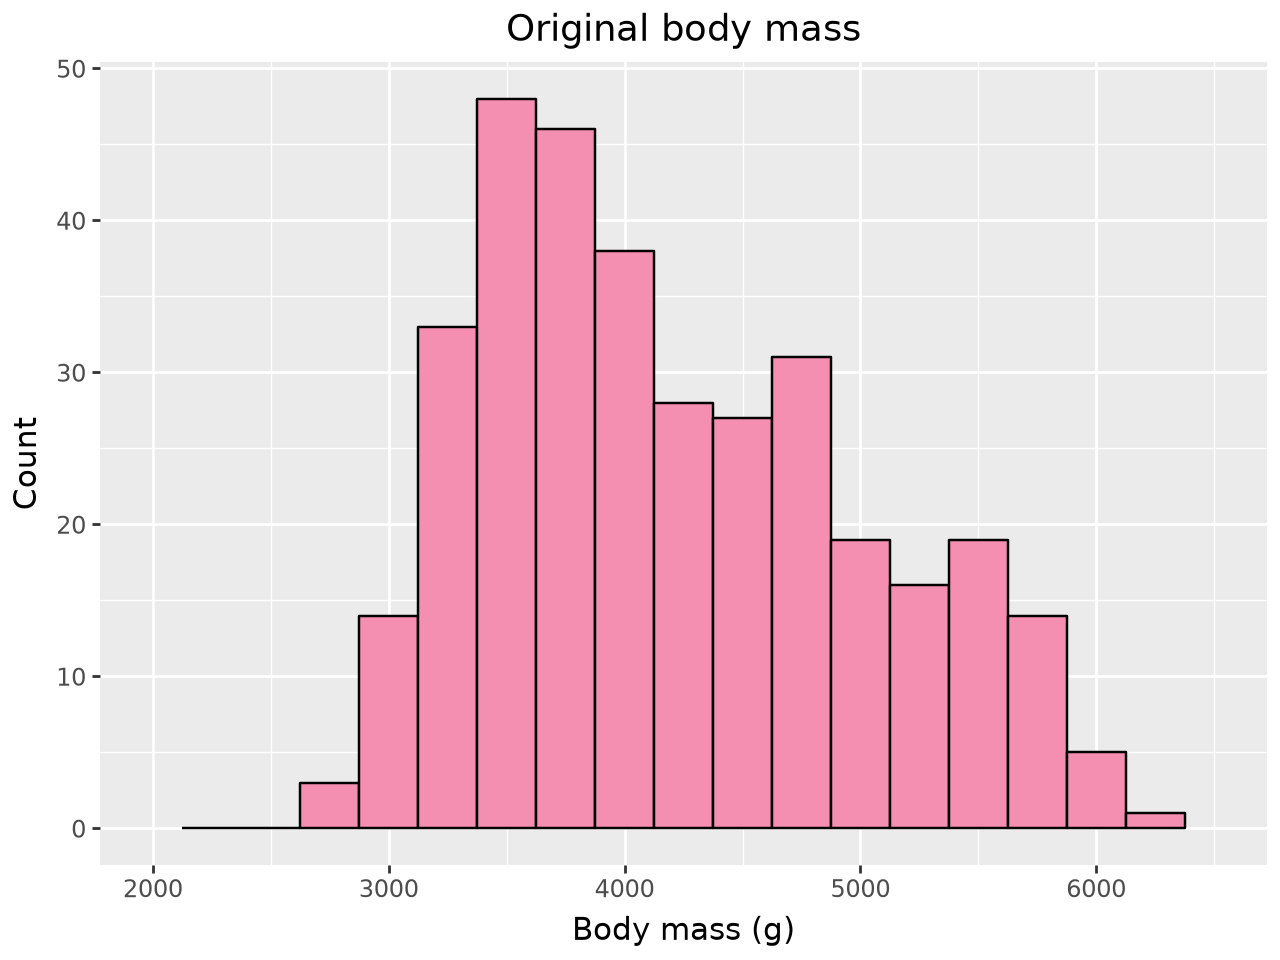

In [36]:
(
    ggplot(df_x, aes(x="mass"))
    + geom_histogram(binwidth=250, fill="#F48FB1", color="black")
    + scale_x_continuous(limits=(2000, 6500))
    + labs(
        title="Original body mass",
        x="Body mass (g)",
        y="Count"
    )
)

9.3. Kiểm tra dự đoán bằng tính toán và hai histogram dùng cùng bin edges và cùng trục
ngang.



9.5. So sánh median và IQR của hai bộ dữ liệu

C:\Users\Windows\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\plotnine\layer.py:374: PlotnineWarning: geom_histogram : Removed 2 rows containing missing values.


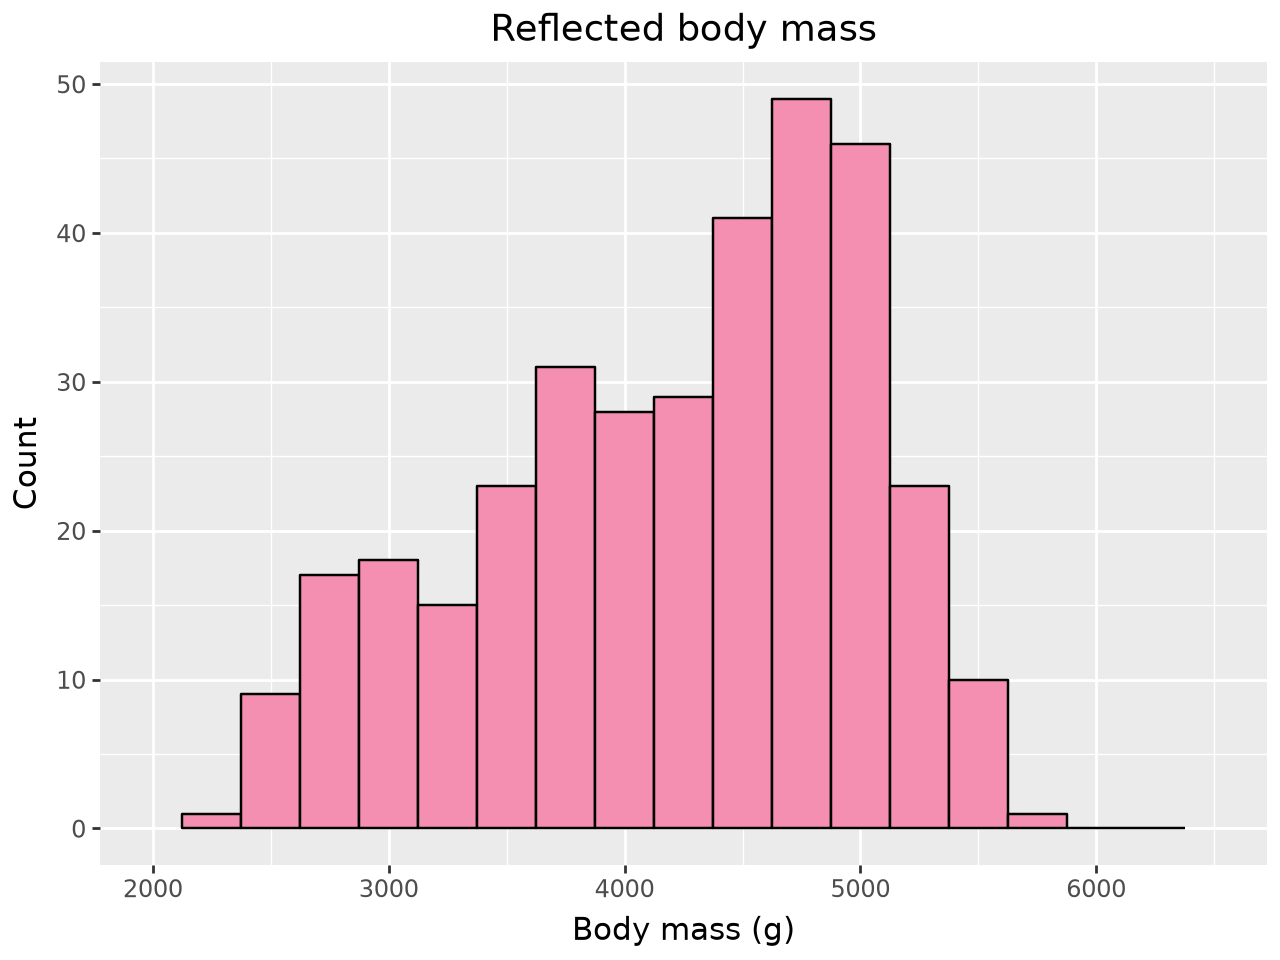

In [37]:
(
    ggplot(df_star, aes(x="mass"))
    + geom_histogram(binwidth=250, fill="#F48FB1", color="black")
    + scale_x_continuous(limits=(2000, 6500))
    + labs(
        title="Reflected body mass",
        x="Body mass (g)",
        y="Count"
    )
)

In [38]:
result = pd.DataFrame({
    "Original": [
        x.mean(),
        x.median(),
        x.std(),
        x.quantile(0.75) - x.quantile(0.25)
    ],
    "x_star": [
        x_star.mean(),
        x_star.median(),
        x_star.std(),
        x_star.quantile(0.75) - x_star.quantile(0.25)
    ]
}, index=["Mean", "Median", "Sample SD", "IQR"])

print(result.round(2))

           Original   x_star
Mean        4201.75  4201.75
Median      4050.00  4353.51
Sample SD    801.95   801.95
IQR         1200.00  1200.00


C:\Users\Windows\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\plotnine\layer.py:374: PlotnineWarning: geom_histogram : Removed 4 rows containing missing values.


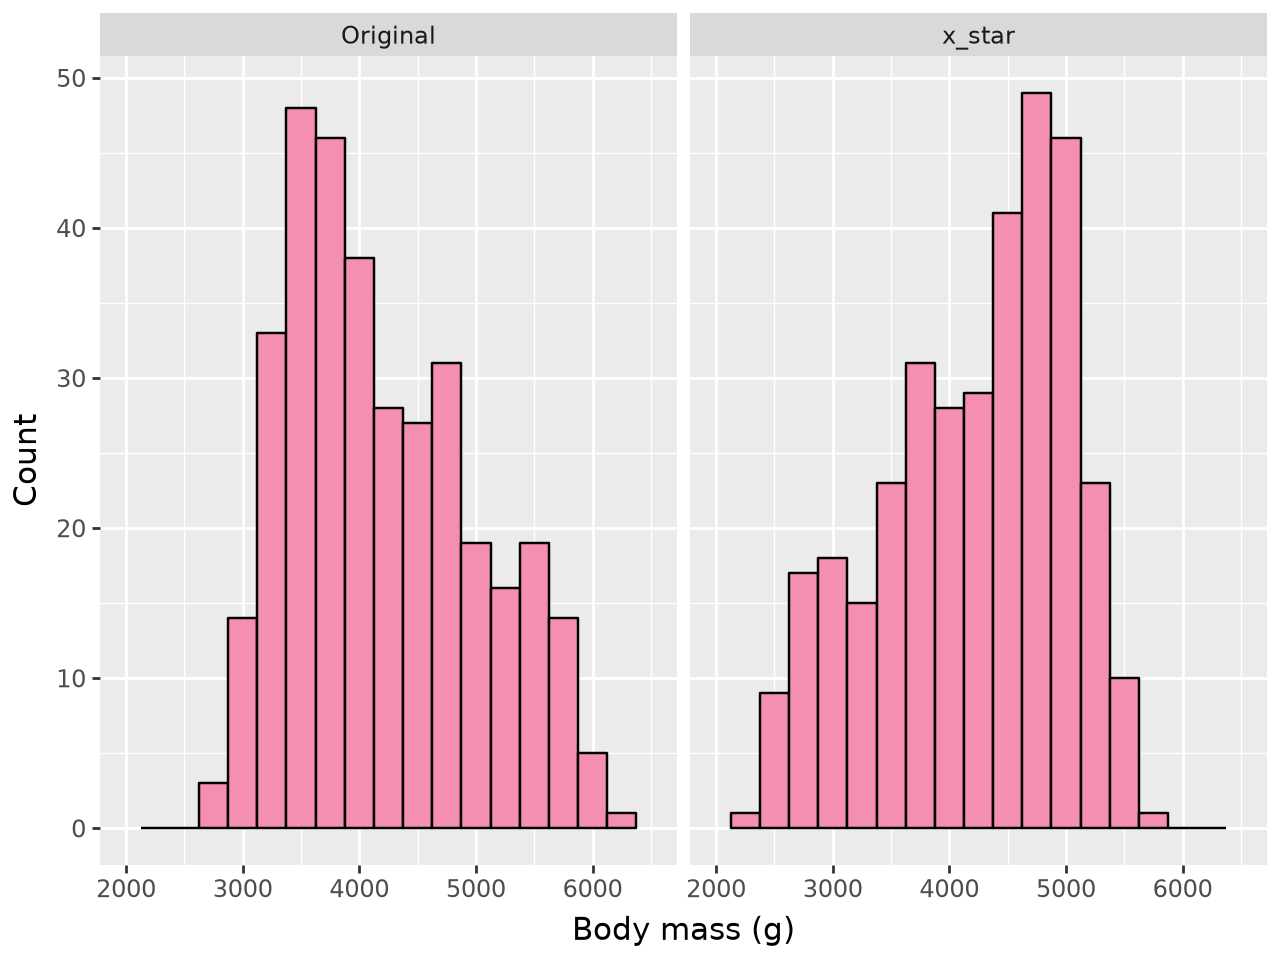

In [39]:
df_plot = pd.DataFrame({
    "mass": pd.concat([x, x_star], ignore_index=True),
    "group": ["Original"] * len(x) + ["x_star"] * len(x_star)
})

(
    ggplot(df_plot, aes(x="mass"))
    + geom_histogram(
        binwidth=250,
        fill="#F48FB1",
        color="black"
    )
    + facet_wrap("~group")
    + scale_x_continuous(limits=(2000, 6500))
    + labs(
        x="Body mass (g)",
        y="Count"
    )
)

Bài 10 — Outlier hay lỗi dữ liệu?

10.1. histogram hoặc dot plot của gpa, tìm quan sát vượt ngoài miền GPA 0–4.


C:\Users\Windows\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\plotnine\layer.py:374: PlotnineWarning: geom_histogram : Removed 2 rows containing missing values.


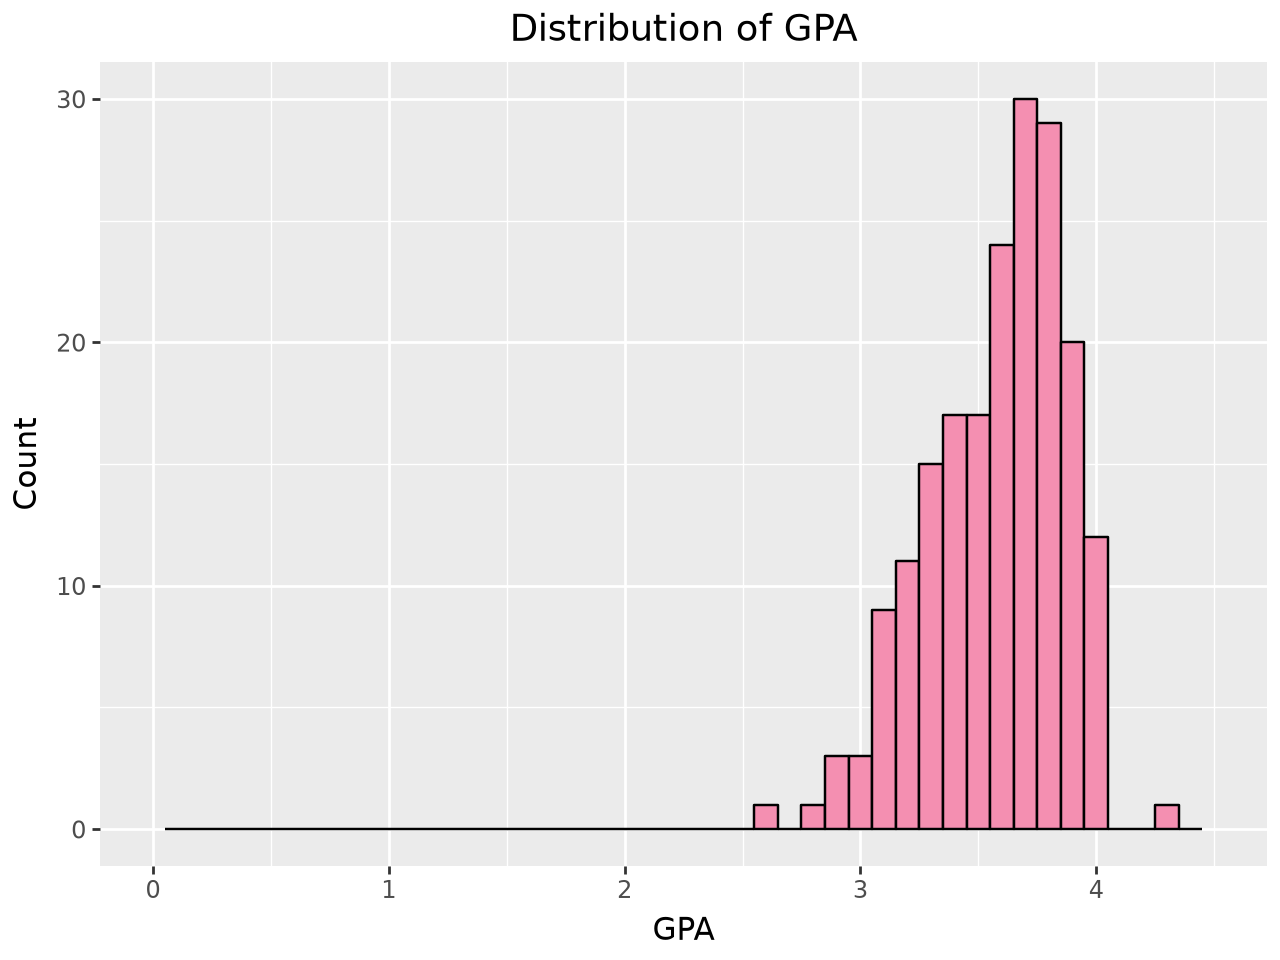

In [42]:
import pandas as pd
from plotnine import *

study = pd.read_csv("gpa_study_hours.csv")
gpa = study["gpa"].dropna()

(
    ggplot(pd.DataFrame({"gpa": gpa}), aes(x="gpa"))
    + geom_histogram(binwidth=0.1, fill="#F48FB1", color="black")
    + scale_x_continuous(limits=(0, 4.5))
    + labs(
        title="Distribution of GPA",
        x="GPA",
        y="Count"
    )
)

In [43]:
outliers = gpa[(gpa < 0) | (gpa > 4)]

print("GPA outside 0–4:")
print(outliers)

GPA outside 0–4:
79    4.3
Name: gpa, dtype: float64


10.2.Tính trên toàn bộ dữ liệu:
• mean;
• median;
• sample SD;
• IQR.

In [44]:
mean_before = gpa.mean()
median_before = gpa.median()
sd_before = gpa.std()
iqr_before = gpa.quantile(0.75) - gpa.quantile(0.25)

print(f"Mean = {mean_before:.4f}")
print(f"Median = {median_before:.4f}")
print(f"Sample SD = {sd_before:.4f}")
print(f"IQR = {iqr_before:.4f}")

Mean = 3.5862
Median = 3.6200
Sample SD = 0.2855
IQR = 0.4000


10.3. Dựa trên documentation của dataset, đánh dấu quan sát GPA > 4 là documented
data error, loại đúng quan sát đó rồi tính lại bốn đại lượng.


In [45]:
gpa_clean = gpa[gpa <= 4]

mean_after = gpa_clean.mean()
median_after = gpa_clean.median()
sd_after = gpa_clean.std()
iqr_after = gpa_clean.quantile(0.75) - gpa_clean.quantile(0.25)

print(f"Mean = {mean_after:.4f}")
print(f"Median = {median_after:.4f}")
print(f"Sample SD = {sd_after:.4f}")
print(f"IQR = {iqr_after:.4f}")

Mean = 3.5824
Median = 3.6150
Sample SD = 0.2815
IQR = 0.4000


10.4.Với mỗi đại lượng, tính cả:
• thay đổi tuyệt đối;
• thay đổi tương đối (%).


C:\Users\Windows\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\plotnine\layer.py:374: PlotnineWarning: geom_histogram : Removed 2 rows containing missing values.


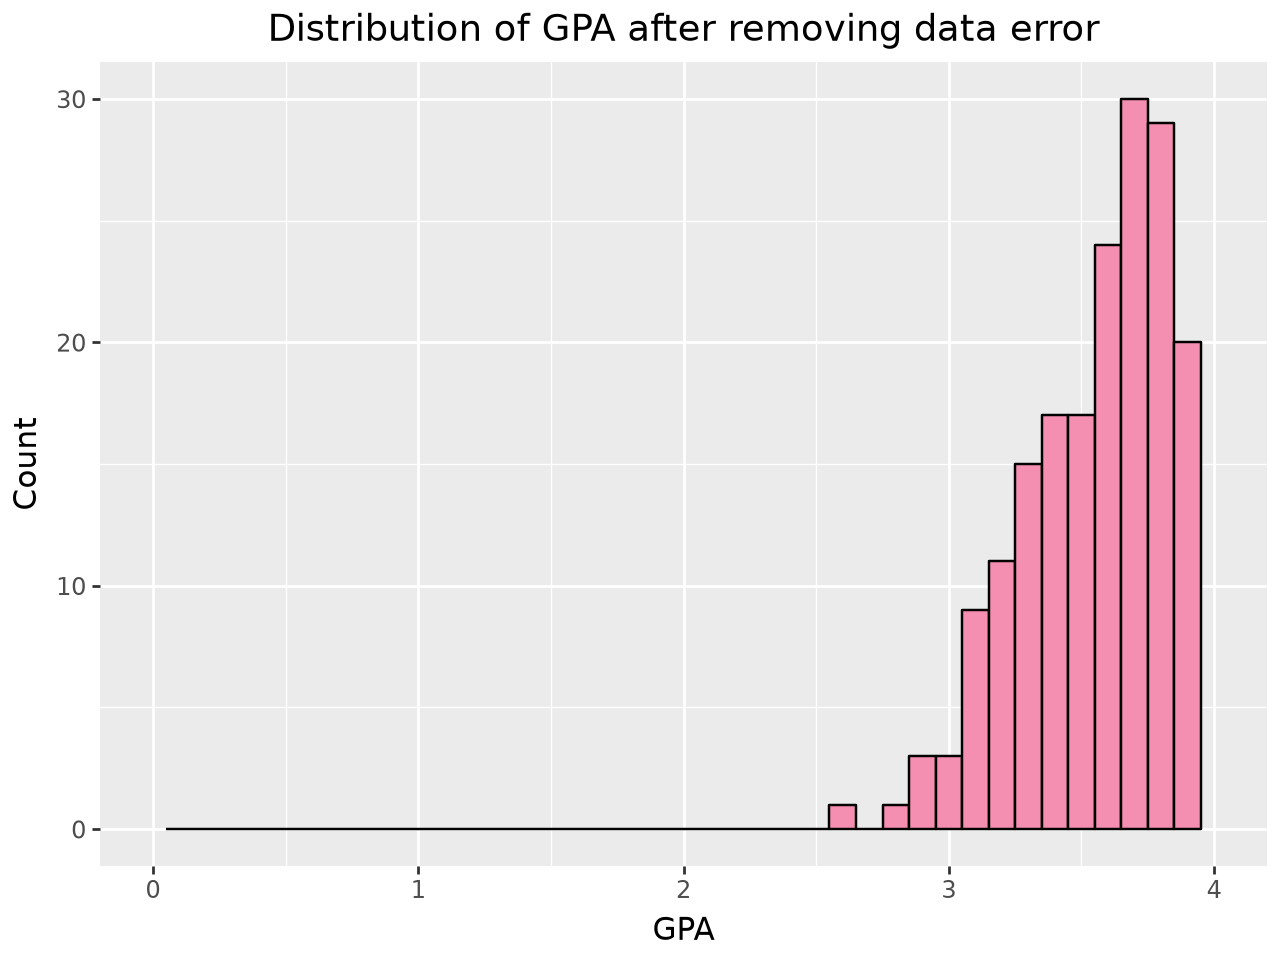

In [46]:
(
    ggplot(pd.DataFrame({"gpa": gpa_clean}), aes(x="gpa"))
    + geom_histogram(binwidth=0.1, fill="#F48FB1", color="black")
    + scale_x_continuous(limits=(0, 4))
    + labs(
        title="Distribution of GPA after removing data error",
        x="GPA",
        y="Count"
    )
)

In [47]:
results = pd.DataFrame({
    "Before": [mean_before, median_before, sd_before, iqr_before],
    "After": [mean_after, median_after, sd_after, iqr_after]
}, index=["Mean", "Median", "Sample SD", "IQR"])

results["Absolute change"] = results["After"] - results["Before"]

results["Relative change (%)"] = (
    results["Absolute change"] / results["Before"] * 100
)

print(results.round(4))

           Before   After  Absolute change  Relative change (%)
Mean       3.5862  3.5824          -0.0037              -0.1037
Median     3.6200  3.6150          -0.0050              -0.1381
Sample SD  0.2855  0.2815          -0.0040              -1.3932
IQR        0.4000  0.4000           0.0000               0.0000
